# HW4
DSCI 552

Name: Ruikun Zhang
GitHub Username: XOBECIUJ
USC ID: 6347-9436-32

In [1]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from sklearn.linear_model import LogisticRegression
from sklearn.feature_selection import RFE
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import StratifiedKFold, GridSearchCV, cross_val_score
from sklearn.naive_bayes import GaussianNB, MultinomialNB
from sklearn.metrics import confusion_matrix, accuracy_score, roc_auc_score, roc_curve
from sklearn.metrics import RocCurveDisplay, ConfusionMatrixDisplay

warnings.filterwarnings('ignore')

## 1. Feature creation (from HW3)
not submitted for grading, just need this to build the features for problem 2

In [2]:
data_dir = '../data/AReM'
folders = ['bending1', 'bending2', 'cycling', 'lying', 'sitting', 'standing', 'walking']

# some files use spaces instead of commas so just handle both
def read_file(path):
    rows = []
    for line in open(path):
        if line.startswith('#') or line.strip() == '':
            continue
        line = line.replace(',', ' ')
        rows.append([float(v) for v in line.split()])
    rows = np.array(rows)
    return rows[:, 1:]   # drop time col

data = []   # (activity, file number, array)
for f in folders:
    for i in range(1, 16):
        path = os.path.join(data_dir, f, 'dataset' + str(i) + '.csv')
        if os.path.exists(path):
            data.append((f, i, read_file(path)))

print(len(data))

88


In [3]:
# test = dataset 1,2 for bending, 1,2,3 for others
test_mask = []
for f, i, a in data:
    if 'bending' in f:
        test_mask.append(i <= 2)
    else:
        test_mask.append(i <= 3)
test_mask = np.array(test_mask)
train_mask = ~test_mask

activity = np.array([f for f, i, a in data])
y = np.array([1 if 'bending' in f else 0 for f in activity])

print('train', train_mask.sum(), 'test', test_mask.sum())

train 69 test 19


In [4]:
feat_names = ['min', 'max', 'mean', 'median', 'std', 'q1', 'q3']

def get_features(a, l=1):
    # split every series into l pieces and get 7 stats from each piece
    feats = []
    pieces = np.array_split(a, l)
    for p in pieces:
        for j in range(6):
            x = p[:, j]
            feats += [x.min(), x.max(), x.mean(), np.median(x), x.std(),
                      np.percentile(x, 25), np.percentile(x, 75)]
    return feats

def get_names(l=1):
    cols = []
    for p in range(1, l + 1):
        for j in range(1, 7):
            for s in feat_names:
                if l == 1:
                    cols.append(s + str(j))
                else:
                    cols.append(s + str(j) + '_part' + str(p))
    return cols

df1 = pd.DataFrame([get_features(a) for f, i, a in data], columns=get_names(1))
df1.head()

,min1,max1,mean1,median1,std1,q11,q31,min2,max2,mean2,...,std5,q15,q35,min6,max6,mean6,median6,std6,q16,q36
0,37.25,45.00,40.624792,40.50,1.475428,39.25,42.00,0.0,1.30,0.358604,...,2.186168,33.0000,36.00,0.0,1.92,0.570583,0.43,0.582308,0.0,1.30
1,38.00,45.67,42.812812,42.50,1.434054,42.00,43.67,0.0,1.22,0.372437,...,1.993175,32.0000,34.50,0.0,3.11,0.571083,0.43,0.600383,0.0,1.30
2,35.00,47.40,43.954500,44.33,1.557210,43.00,45.00,0.0,1.70,0.426250,...,1.997520,35.3625,36.50,0.0,1.79,0.493292,0.43,0.512971,0.0,0.94
3,33.00,47.75,42.179812,43.50,3.666840,39.15,45.00,0.0,3.00,0.696042,...,3.845436,30.4575,36.33,0.0,2.18,0.613521,0.50,0.523771,0.0,1.00
4,33.00,45.75,41.678063,41.75,2.241152,41.33,42.75,0.0,2.83,0.535979,...,2.408514,28.4575,31.25,0.0,1.79,0.383292,0.43,0.388759,0.0,0.50


## 2. Time Series Classification Part 2
### (a) Binary classification with logistic regression
#### i. scatter plots

using min, mean, max (picked in HW3) for series 1, 2, 6

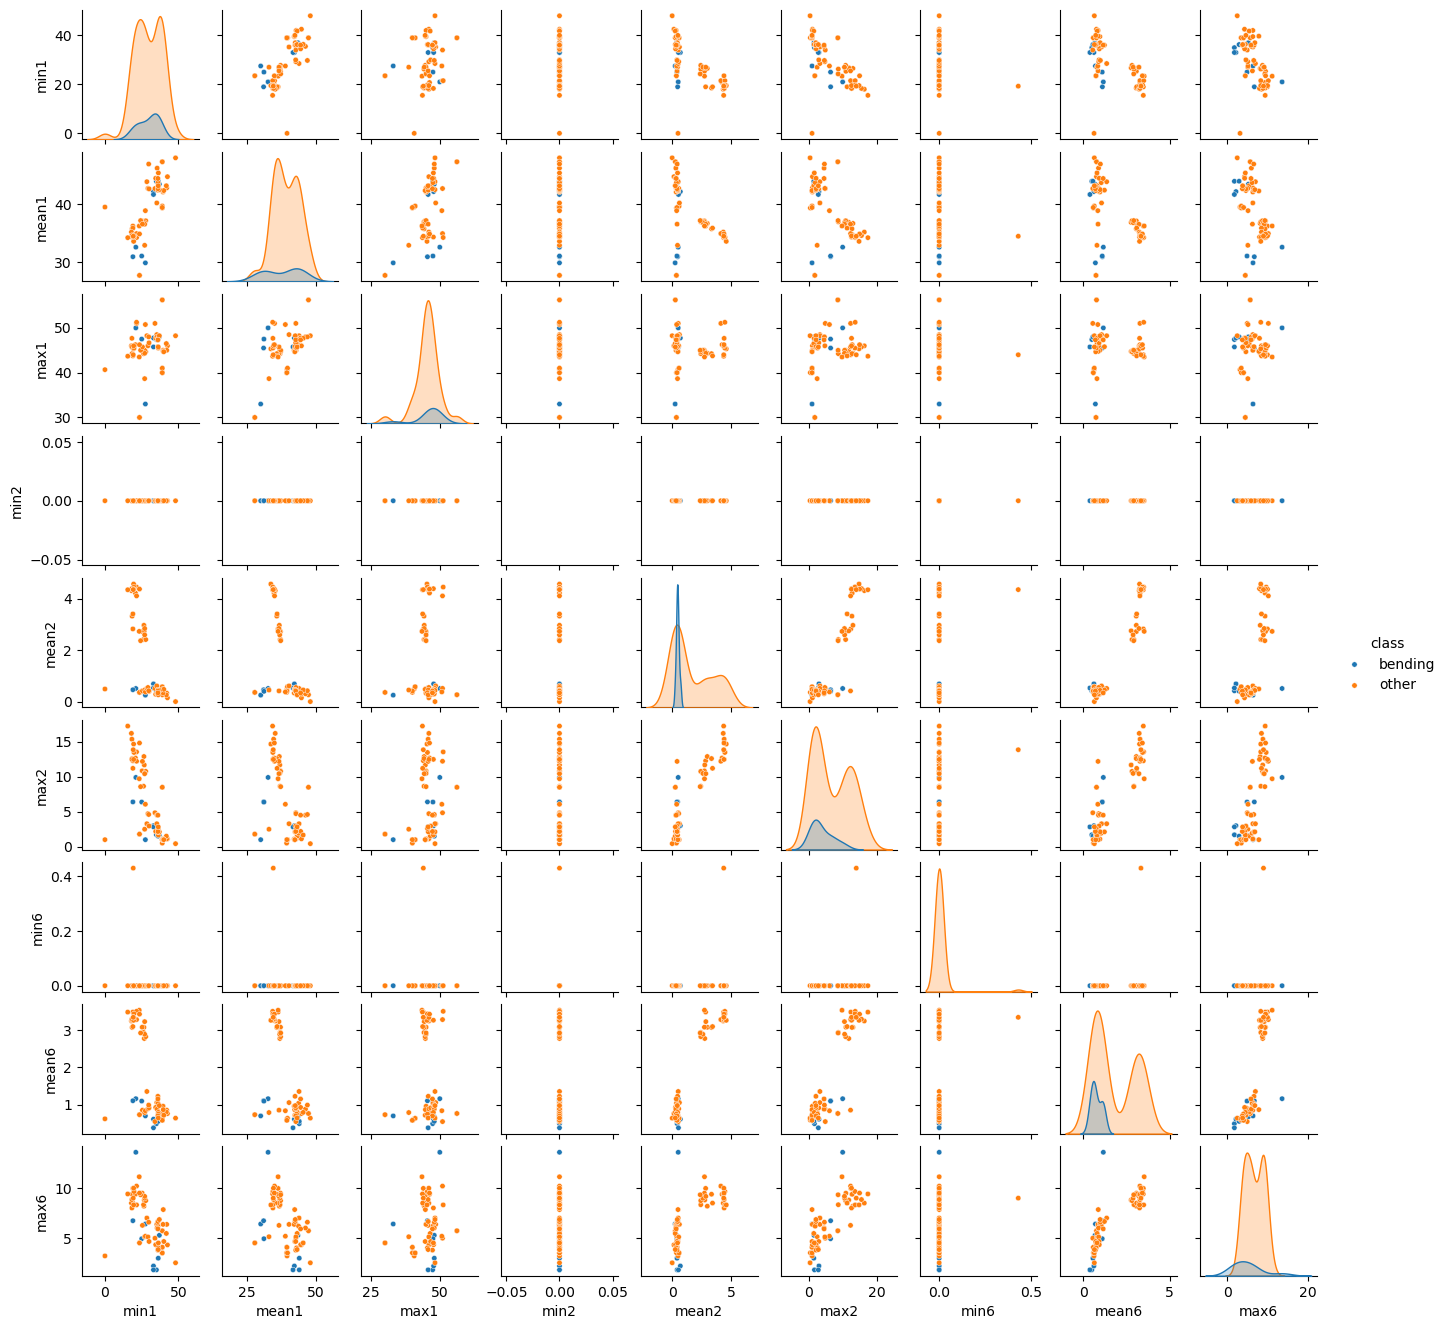

In [5]:
y_train = y[train_mask]
y_test = y[test_mask]

cols = []
for j in [1, 2, 6]:
    for s in ['min', 'mean', 'max']:
        cols.append(s + str(j))

plot_df = df1.loc[train_mask, cols].copy()
plot_df['class'] = np.where(y_train == 1, 'bending', 'other')
sns.pairplot(plot_df, hue='class', height=1.5, plot_kws={'s': 15})
plt.show()

bending points mostly sit in the low part of the var series (series 2 and 6). cycling/walking are way higher there. but lying/sitting/standing overlap with bending in a lot of the plots, so its not perfectly separated in any single plot. min of series 2 and 6 is basically 0 for everything so those are kinda useless

#### ii. break into 2 parts

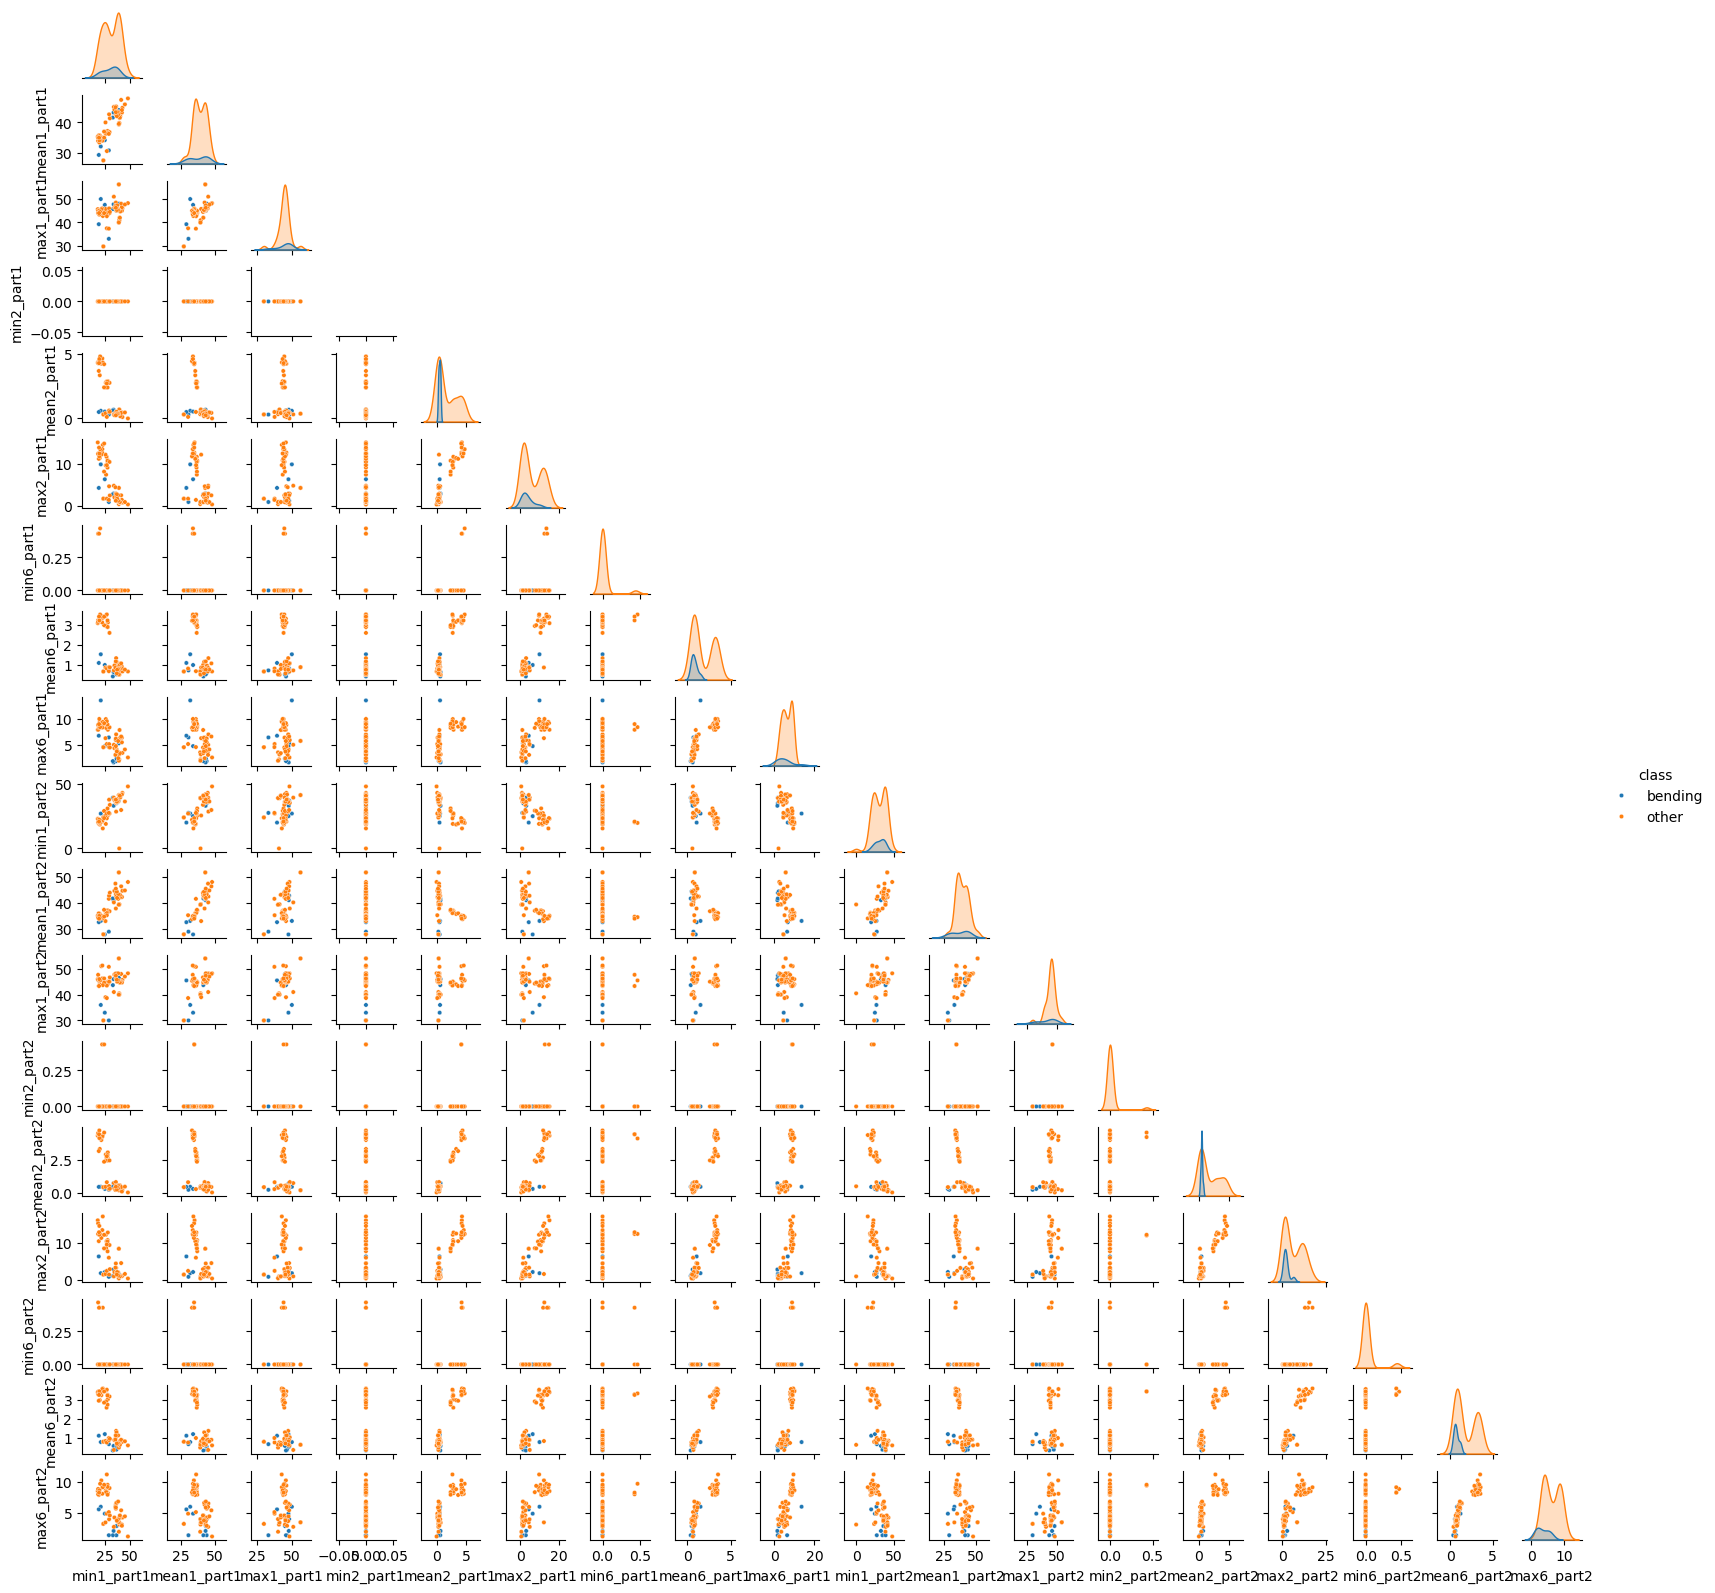

In [6]:
df2 = pd.DataFrame([get_features(a, 2) for f, i, a in data], columns=get_names(2))

cols2 = []
for p in [1, 2]:
    for j in [1, 2, 6]:
        for s in ['min', 'mean', 'max']:
            cols2.append(s + str(j) + '_part' + str(p))

plot_df2 = df2.loc[train_mask, cols2].copy()
plot_df2['class'] = np.where(y_train == 1, 'bending', 'other')
sns.pairplot(plot_df2, hue='class', height=0.9, plot_kws={'s': 10}, corner=True)
plt.show()

looks pretty much the same as (i). part1 and part2 of the same feature are highly correlated so the extra plots dont really add new info. no considerable difference i think

#### iii. pick (l, p) with 5 fold CV

right way vs wrong way:
- wrong way: do the feature selection (RFE / p-values) on the whole training set first, then run CV on the selected features. the validation folds already "saw" the selection step so the CV accuracy is too optimistic
- right way: feature selection (and scaling) has to happen inside each fold using only that fold's training part, then evaluate on the held out part

only 9 bending vs 60 other in train so i use stratified kfold so each fold has some bending

In [7]:
# features for every l, takes a few sec
X_all = {}
for l in range(1, 21):
    X_all[l] = np.array([get_features(a, l) for f, i, a in data])

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=1)
p_list = list(range(1, 11))
cv_results = pd.DataFrame(index=range(1, 21), columns=p_list, dtype=float)

for l in range(1, 21):
    X = X_all[l][train_mask]
    acc = np.zeros((5, len(p_list)))
    fold = 0
    for tr, va in skf.split(X, y_train):
        scaler = StandardScaler()
        X_tr = scaler.fit_transform(X[tr])
        X_va = scaler.transform(X[va])
        # run RFE all the way down to 1 feature, then ranking tells us the top p for any p
        rfe = RFE(LogisticRegression(penalty=None, max_iter=100), n_features_to_select=1)
        rfe.fit(X_tr, y_train[tr])
        for k, p in enumerate(p_list):
            sel = rfe.ranking_ <= p
            lr = LogisticRegression(penalty=None, max_iter=100)
            lr.fit(X_tr[:, sel], y_train[tr])
            acc[fold, k] = lr.score(X_va[:, sel], y_train[va])
        fold += 1
    cv_results.loc[l] = acc.mean(axis=0)

cv_results.round(3)

,1,2,3,4,5,6,7,8,9,10
1,0.929,0.943,0.913,0.899,0.957,0.971,0.957,0.986,0.986,0.986
2,0.914,0.927,0.927,0.971,0.957,0.943,0.929,0.943,0.927,0.927
3,0.957,0.897,0.942,0.971,0.971,0.971,0.943,0.957,0.942,0.942
4,0.957,0.914,0.929,0.957,0.929,0.929,0.929,0.943,0.943,0.929
5,0.943,0.929,0.899,0.927,0.942,0.926,0.926,0.927,0.913,0.913
6,0.914,0.899,0.929,0.943,0.943,0.957,0.957,0.943,0.956,0.927
7,0.900,0.900,0.913,0.884,0.884,0.898,0.898,0.913,0.898,0.913
8,0.914,0.886,0.885,0.914,0.913,0.927,0.912,0.898,0.884,0.884
9,0.899,0.914,0.929,0.929,0.943,0.957,0.956,0.956,0.927,0.913
10,0.900,0.886,0.900,0.929,0.943,0.929,0.914,0.929,0.929,0.943


In [8]:
best = cv_results.stack().idxmax()
best_l = int(best[0])
best_p = int(best[1])
print('best l =', best_l, ' best p =', best_p, ' cv acc =', cv_results.loc[best_l, best_p])

best l = 1  best p = 8  cv acc = 0.9857142857142858


#### iv. confusion matrix, ROC, AUC on train + coefficients and p-values

In [9]:
X_train = X_all[best_l][train_mask]
X_test = X_all[best_l][test_mask]

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

rfe = RFE(LogisticRegression(penalty=None, max_iter=100), n_features_to_select=best_p)
rfe.fit(X_train_s, y_train)
sel = rfe.support_
sel_names = np.array(get_names(best_l))[sel]
print(sel_names)

model = LogisticRegression(penalty=None, max_iter=100)
model.fit(X_train_s[:, sel], y_train)

# sklearn has no p-values so use statsmodels for those
glm = sm.GLM(y_train, sm.add_constant(X_train_s[:, sel]), family=sm.families.Binomial()).fit(maxiter=100)
coef_table = pd.DataFrame({'beta (sklearn)': np.append(model.intercept_, model.coef_[0]),
                           'beta (statsmodels)': glm.params,
                           'p-value': glm.pvalues},
                          index=['intercept'] + list(sel_names))
coef_table

['q31' 'q33' 'max4' 'q14' 'min5' 'max5' 'mean5' 'q16']


,beta (sklearn),beta (statsmodels),p-value
intercept,-12.137336,-37.553999,0.998821
q31,-3.677558,-9.908033,0.999751
q33,-2.018473,-5.733825,0.999812
max4,2.909964,9.776656,0.999906
q14,-3.118972,-6.986995,0.999937
min5,4.621017,18.996880,0.999843
max5,5.063211,16.680011,0.999764
mean5,3.184319,3.192555,0.999979
q16,-3.133755,-15.406442,0.999857


[[60  0]
 [ 0  9]]
train acc 1.0
train AUC 1.0


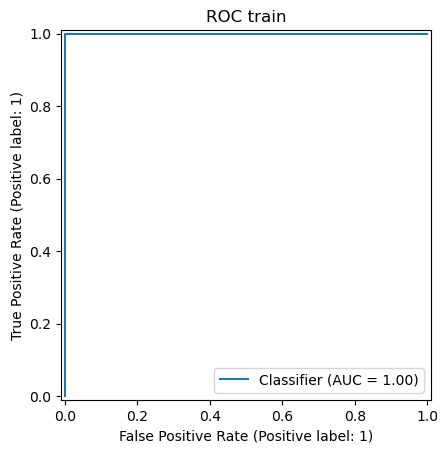

In [10]:
train_pred = model.predict(X_train_s[:, sel])
train_prob = model.predict_proba(X_train_s[:, sel])[:, 1]

print(confusion_matrix(y_train, train_pred))
print('train acc', accuracy_score(y_train, train_pred))
print('train AUC', roc_auc_score(y_train, train_prob))

RocCurveDisplay.from_predictions(y_train, train_prob)
plt.title('ROC train')
plt.show()

#### v. test set

In [11]:
test_pred = model.predict(X_test_s[:, sel])
test_prob = model.predict_proba(X_test_s[:, sel])[:, 1]

print(confusion_matrix(y_test, test_pred))
print('test acc', accuracy_score(y_test, test_pred))
print('cv acc', cv_results.loc[best_l, best_p])

[[15  0]
 [ 0  4]]
test acc 1.0
cv acc 0.9857142857142858


test acc is 1.0 (all 15 other + 4 bending correct), cv acc was 0.986 so theyre basically the same, test is even a bit higher. test set is only 19 points though so one mistake would change it by ~5%

#### vi. well separated?

yes. train accuracy is 1.0 so the classes are linearly separable with the selected features. when that happens the MLE doesnt really exist, the likelihood keeps going up as the betas get bigger, so the coefficients blow up (sklearn and statsmodels dont even agree on them) and all the p-values are ~1 because the standard errors are huge. thats the instability. i kept max_iter=100 so it stops early. prediction still works fine but the betas / p-values shouldnt be trusted

#### vii. imbalance / case-control sampling

train bending: 9  other: 60
train
[[60  0]
 [ 0  9]]
acc 1.0  AUC 1.0
test
[[15  0]
 [ 0  4]]
acc 1.0  AUC 1.0


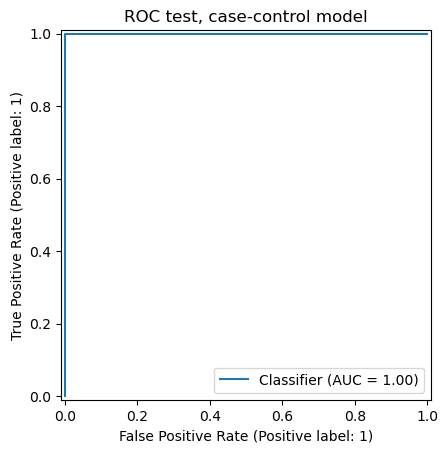

In [12]:
print('train bending:', y_train.sum(), ' other:', (y_train == 0).sum())

# take all bending (cases) + same number of random others (controls)
np.random.seed(1)
cases = np.where(y_train == 1)[0]
controls = np.random.choice(np.where(y_train == 0)[0], len(cases), replace=False)
idx = np.concatenate([cases, controls])

cc_model = LogisticRegression(penalty=None, max_iter=100)
cc_model.fit(X_train_s[idx][:, sel], y_train[idx])

# fix intercept: b0 + log(pi/(1-pi)) - log(pi_tilde/(1-pi_tilde)), pi_tilde = 0.5 here
pi = y_train.mean()
cc_model.intercept_ = cc_model.intercept_ + np.log(pi / (1 - pi)) - np.log(0.5 / 0.5)

for name, Xs, yy in [('train', X_train_s, y_train), ('test', X_test_s, y_test)]:
    pr = cc_model.predict(Xs[:, sel])
    pb = cc_model.predict_proba(Xs[:, sel])[:, 1]
    print(name)
    print(confusion_matrix(yy, pr))
    print('acc', accuracy_score(yy, pr), ' AUC', roc_auc_score(yy, pb))

RocCurveDisplay.from_predictions(y_test, cc_model.predict_proba(X_test_s[:, sel])[:, 1])
plt.title('ROC test, case-control model')
plt.show()

yes its imbalanced, 9 bending vs 60 other in train (~13% bending). did case-control sampling: all 9 bending + 9 random other, fit logistic regression on those 18, then corrected the intercept with log(pi/(1-pi)) where pi = 9/69.

the case-control model still gets everything right on train and test (acc 1.0, AUC 1.0), same as the original. so here it didnt really change anything, the classes are easy to separate anyway

### (b) L1-penalized logistic regression
#### i. CV over l and C

In [13]:
C_list = np.logspace(-2, 2, 15)
l1_rows = []
l1_models = {}
for l in range(1, 21):
    pipe = make_pipeline(StandardScaler(), LogisticRegression(penalty='l1', solver='liblinear'))
    gs = GridSearchCV(pipe, {'logisticregression__C': C_list}, cv=skf, scoring='accuracy')
    gs.fit(X_all[l][train_mask], y_train)
    l1_rows.append([l, gs.best_params_['logisticregression__C'], gs.best_score_])
    l1_models[l] = gs.best_estimator_

l1_df = pd.DataFrame(l1_rows, columns=['l', 'best C', 'cv acc']).set_index('l')
l1_df.round(3)

,best C,cv acc
l,,
1,0.268,0.971
2,1.000,0.957
3,100.000,0.986
4,0.518,0.957
5,51.795,0.943
6,51.795,0.943
7,7.197,0.957
8,0.268,0.929
9,0.268,0.929


best l 3  C 100.0  cv acc 0.9857142857142858
nonzero coefs: 14 / 126
[[15  0]
 [ 1  3]]
test acc 0.9473684210526315  test AUC 0.9833333333333334


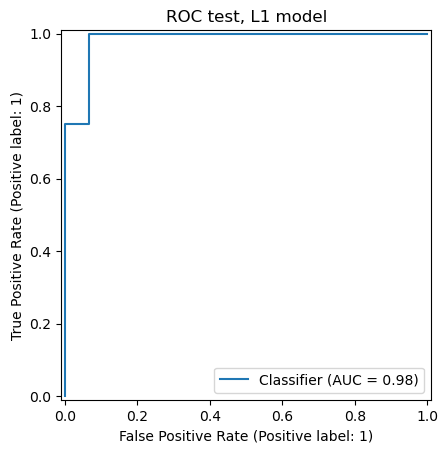

In [14]:
best_l1 = l1_df['cv acc'].idxmax()
l1_model = l1_models[best_l1]
print('best l', best_l1, ' C', l1_df.loc[best_l1, 'best C'], ' cv acc', l1_df.loc[best_l1, 'cv acc'])
print('nonzero coefs:', (l1_model[-1].coef_ != 0).sum(), '/', X_all[best_l1].shape[1])

pred = l1_model.predict(X_all[best_l1][test_mask])
prob = l1_model.predict_proba(X_all[best_l1][test_mask])[:, 1]
print(confusion_matrix(y_test, pred))
print('test acc', accuracy_score(y_test, pred), ' test AUC', roc_auc_score(y_test, prob))
RocCurveDisplay.from_predictions(y_test, prob)
plt.title('ROC test, L1 model')
plt.show()

best is l = 3 with C = 100 (lambda = 1/C = 0.01), cv acc 0.986. only 14 of the 126 coefs are nonzero. on test it gets 0.947 acc (missed 1 bending) and AUC 0.983. note a lot of (l, C) combos are close to each other in cv acc, like l=1 gets 0.971

#### ii. compare

cv accuracy is the same (0.986 for both). on the test set the p-value/RFE one got 1.0 and L1 got 0.947 but thats just 1 instance out of 19 so i wouldnt say one is really better in performance.

L1 is way easier to implement tho, its just a pipeline + GridSearchCV and the penalty does the feature selection for you. the RFE/p-value way needs the selection inside every fold manually and the p-values are useless here anyway since the classes are separable. so i'd go with L1

### (c) Multi-class
#### i. L1 multinomial regression

In [15]:
y_multi = np.array([folders.index(f) for f in activity])
ym_train = y_multi[train_mask]
ym_test = y_multi[test_mask]

C_list_m = [0.1, 0.3, 1, 3, 10]
m_rows = []
m_models = {}
for l in range(1, 21):
    pipe = make_pipeline(StandardScaler(), LogisticRegression(penalty='l1', solver='saga', max_iter=1000, tol=1e-3))
    gs = GridSearchCV(pipe, {'logisticregression__C': C_list_m}, cv=skf, scoring='accuracy', n_jobs=-1)
    gs.fit(X_all[l][train_mask], ym_train)
    m_rows.append([l, gs.best_params_['logisticregression__C'], gs.best_score_])
    m_models[l] = gs.best_estimator_

m_df = pd.DataFrame(m_rows, columns=['l', 'best C', 'cv acc']).set_index('l')
m_df.round(3)

,best C,cv acc
l,,
1,1.0,0.929
2,3.0,0.898
3,10.0,0.857
4,1.0,0.842
5,3.0,0.870
6,10.0,0.871
7,10.0,0.842
8,10.0,0.856
9,0.3,0.813


best l 1  cv acc 0.9285714285714286
test error 0.10526315789473684


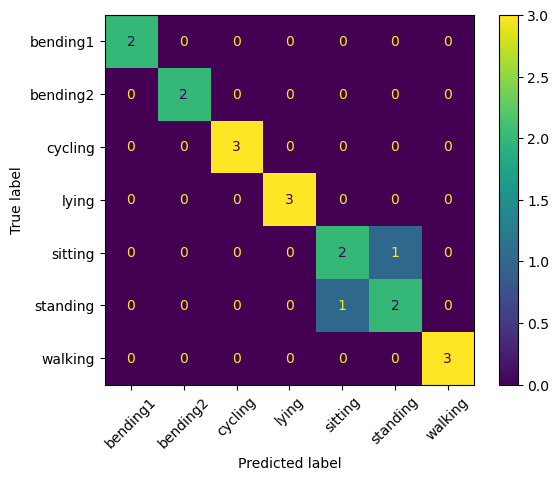

In [16]:
best_lm = m_df['cv acc'].idxmax()
m_model = m_models[best_lm]
Xm_test = X_all[best_lm][test_mask]
pred_m = m_model.predict(Xm_test)
prob_m = m_model.predict_proba(Xm_test)
print('best l', best_lm, ' cv acc', m_df.loc[best_lm, 'cv acc'])
print('test error', 1 - accuracy_score(ym_test, pred_m))

ConfusionMatrixDisplay.from_predictions(ym_test, pred_m, labels=range(7), display_labels=folders, xticks_rotation=45)
plt.show()

multiclass confusion matrix is just K x K, row = true class, col = predicted. for ROC you do one-vs-rest: treat class k as positive and everything else negative, use the predicted prob of class k -> one curve per class. can average the AUCs (macro avg)

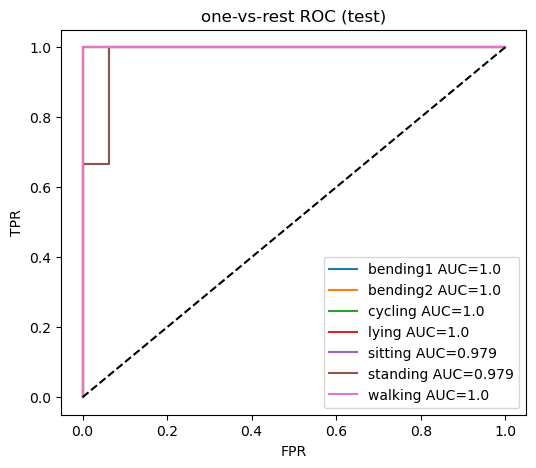

macro AUC 0.9940476190476192


In [17]:
plt.figure(figsize=(6, 5))
for k in range(7):
    yk = (ym_test == k).astype(int)
    fpr, tpr, _ = roc_curve(yk, prob_m[:, k])
    plt.plot(fpr, tpr, label=folders[k] + ' AUC=' + str(round(roc_auc_score(yk, prob_m[:, k]), 3)))
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('FPR')
plt.ylabel('TPR')
plt.legend()
plt.title('one-vs-rest ROC (test)')
plt.show()

print('macro AUC', roc_auc_score(ym_test, prob_m, multi_class='ovr', labels=range(7)))

best l = 1 (C = 1), cv acc 0.929. test error = 0.105, 2 of 19 wrong: one sitting predicted as standing and one standing predicted as sitting. bending, cycling, walking all correct. macro AUC is 0.994

#### ii. Naive Bayes (Gaussian and Multinomial)

In [18]:
nb_df = pd.DataFrame(index=range(1, 21), columns=['gaussian', 'multinomial'], dtype=float)
for l in range(1, 21):
    X = X_all[l][train_mask]
    nb_df.loc[l, 'gaussian'] = cross_val_score(GaussianNB(), X, ym_train, cv=skf).mean()
    # all features are >= 0 so multinomial NB is ok to run
    nb_df.loc[l, 'multinomial'] = cross_val_score(MultinomialNB(), X, ym_train, cv=skf).mean()
nb_df.round(3)

,gaussian,multinomial
1,0.870,0.842
2,0.856,0.784
3,0.741,0.798
4,0.755,0.812
5,0.710,0.784
6,0.698,0.784
7,0.740,0.798
8,0.698,0.812
9,0.625,0.768
10,0.712,0.768


gaussian  best l 1  cv acc 0.87  test error 0.105
multinomial  best l 1  cv acc 0.842  test error 0.105


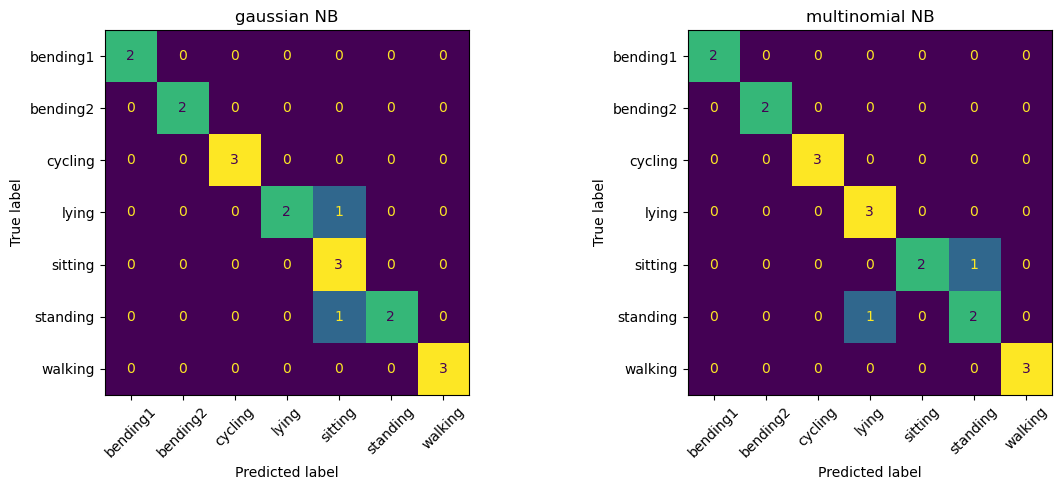

In [19]:
fig, ax = plt.subplots(1, 2, figsize=(12, 5))
for n, (name, clf) in enumerate([('gaussian', GaussianNB()), ('multinomial', MultinomialNB())]):
    l = nb_df[name].idxmax()
    clf.fit(X_all[l][train_mask], ym_train)
    pr = clf.predict(X_all[l][test_mask])
    print(name, ' best l', l, ' cv acc', round(nb_df.loc[l, name], 3), ' test error', round(1 - accuracy_score(ym_test, pr), 3))
    ConfusionMatrixDisplay.from_predictions(ym_test, pr, labels=range(7), display_labels=folders,
                                            xticks_rotation=45, ax=ax[n], colorbar=False)
    ax[n].set_title(name + ' NB')
plt.tight_layout()
plt.show()

both pick l = 1. gaussian NB cv acc 0.870, multinomial NB 0.842. both have test error 0.105 (2/19), again the mistakes are between lying/sitting/standing. gaussian is a bit better in cv. both get much worse when l goes up (gaussian drops to ~0.55) bc more features that are correlated with each other breaks the independence assumption

#### iii. which is better

L1 multinomial logistic regression is better here. test error is the same for all 3 (0.105) but the test set is tiny, cv acc is higher for L1 (0.929 vs 0.870 / 0.842) and it handles more features better since the penalty drops the useless ones. also gives nice probabilities for the ROC curves

## 3. ISLR 4.8.3

for QDA with p = 1, class k has X ~ N(mu_k, sigma_k^2), so

f_k(x) = 1/(sqrt(2 pi) sigma_k) * exp( -(x - mu_k)^2 / (2 sigma_k^2) )

posterior:

p_k(x) = pi_k f_k(x) / sum_l pi_l f_l(x)

bayes classifier picks the k with largest p_k(x). the denominator is the same for every k so we just need to maximize pi_k f_k(x), and taking log doesnt change which is biggest:

log(pi_k f_k(x)) = log(pi_k) - log(sqrt(2 pi)) - log(sigma_k) - (x - mu_k)^2 / (2 sigma_k^2)

log(sqrt(2pi)) is the same for all k so drop it. expand the square:

delta_k(x) = - x^2 / (2 sigma_k^2) + x mu_k / sigma_k^2 - mu_k^2 / (2 sigma_k^2) + log(pi_k) - log(sigma_k)

in section 4.4.1 all sigma_k were equal (= sigma) so the -x^2/(2 sigma^2) term was the same for every class and could be dropped, which is why LDA is linear in x. here sigma_k is different for each class so the x^2 term depends on k and can't be dropped. the coefficient on x^2 is -1/(2 sigma_k^2) which is different for different k.

so delta_k(x) is a quadratic function of x, and the decision boundary between class k and class j is where delta_k(x) = delta_j(x), i.e.

(1/(2 sigma_j^2) - 1/(2 sigma_k^2)) x^2 + (mu_k/sigma_k^2 - mu_j/sigma_j^2) x + const = 0

which has a nonzero x^2 term whenever sigma_k != sigma_j. so the bayes classifier is not linear, its quadratic.

## 4. ISLR 4.8.7

two classes, Yes and No.
- pi_yes = 0.8, pi_no = 0.2
- mu_yes = 10, mu_no = 0
- sigma^2 = 36 for both

bayes theorem:

P(Yes | X=4) = pi_yes f_yes(4) / ( pi_yes f_yes(4) + pi_no f_no(4) )

the 1/sqrt(2 pi sigma^2) part is the same in both classes (same variance) so it cancels:

P(Yes | X=4) = 0.8 exp(-(4-10)^2/72) / ( 0.8 exp(-(4-10)^2/72) + 0.2 exp(-(4-0)^2/72) )

= 0.8 exp(-0.5) / ( 0.8 exp(-0.5) + 0.2 exp(-0.2222) )

= 0.4852 / (0.4852 + 0.1601)

checking with code below:

In [20]:
def normal_pdf(x, mu, var):
    return 1 / np.sqrt(2 * np.pi * var) * np.exp(-(x - mu) ** 2 / (2 * var))

num = 0.8 * normal_pdf(4, 10, 36)
den = num + 0.2 * normal_pdf(4, 0, 36)
print(num / den)

0.7518524532975261


so the probability that the company issues a dividend is about **0.752** (75.2%)